In [1]:
# ─── INSTALL DEPENDENCIES (Google Colab) ─────────────────────────────────
!pip install -q sentence-transformers langchain-text-splitters


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 515.1/515.1 kB 18.4 MB/s eta 0:00:00


In [2]:
# ─── UPLOAD FILE (Google Colab) ───────────────────────────────────────────
from google.colab import files
import os

print('Upload 2 file CSV:')
print('  1. dss_trade_agreements_202602201509.csv')
print('  2. dss_trade_agreement_detail_formatted_202602201508.csv')
print()

uploaded = files.upload()

for fname in uploaded:
    print(f'✅ Uploaded: {fname} ({len(uploaded[fname])/1024/1024:.1f} MB)')

# Path otomatis setelah upload
FILE_COVER  = 'dss_trade_agreements_202602201509.csv'
FILE_DETAIL = 'dss_trade_agreement_detail_formatted_202602201508.csv'

print()
print(f'FILE_COVER  : {FILE_COVER}')
print(f'FILE_DETAIL : {FILE_DETAIL}')


Upload 2 file CSV:
  1. dss_trade_agreements_202602201509.csv
  2. dss_trade_agreement_detail_formatted_202602201508.csv



Saving dss_trade_agreement_detail_formatted_202602201508.csv to dss_trade_agreement_detail_formatted_202602201508.csv
Saving dss_trade_agreements_202602201509.csv to dss_trade_agreements_202602201509.csv
✅ Uploaded: dss_trade_agreement_detail_formatted_202602201508.csv (198.3 MB)
✅ Uploaded: dss_trade_agreements_202602201509.csv (0.4 MB)

FILE_COVER  : dss_trade_agreements_202602201509.csv
FILE_DETAIL : dss_trade_agreement_detail_formatted_202602201508.csv


# 🧬 Hybrid Chunking Pipeline (Semantic + Recursive)

Notebook ini mengimplementasikan arsitektur pemotongan tingkat lanjut:
1. **Semantic-First:** Memotong teks berdasarkan kemiripan makna (*cosine similarity*) agar konteks hukum RTA tetap utuh.
2. **The Filter:** Mengecek panjang token dari setiap chunk hasil Semantic.
3. **Recursive Fallback:** Jika ada chunk yang melebihi batas (384 token), chunk raksasa tersebut akan dipotong paksa menggunakan *LangChain Token Splitter* agar aman masuk ke Qdrant.

## Install & Import

In [11]:
import sys
import time
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from langchain_text_splitters import SentenceTransformersTokenTextSplitter

# 1. Load Model Utama
MODEL_NAME  = 'sentence-transformers/all-mpnet-base-v2'
model       = SentenceTransformer(MODEL_NAME)
TOKEN_LIMIT = model.get_max_seq_length()  # 384
SAFE_LIMIT  = TOKEN_LIMIT - 2             # 382 — buffer untuk special tokens [CLS][SEP]

# 2. Setup Recursive Splitter (jaring pengaman)
recursive_splitter = SentenceTransformersTokenTextSplitter(
    model_name=MODEL_NAME,
    chunk_overlap=20,
    tokens_per_chunk=378
)

# Fungsi Penghitung Token
def count_tokens(text):
    return len(model.tokenizer(text)['input_ids'])

print(f'✅ Model & Splitter siap: {MODEL_NAME}')
print(f'📏 Token limit model : {TOKEN_LIMIT}')
print(f'📏 Safe limit        : {SAFE_LIMIT} (dengan buffer special tokens)')


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Model & Splitter siap: sentence-transformers/all-mpnet-base-v2
📏 Token limit model : 384
📏 Safe limit        : 382 (dengan buffer special tokens)


## Load Data & Fungsi Semantic

In [12]:
# ─── LOAD DATA ────────────────────────────────────────────────────────────
DATA_LIMIT = None  # Set angka (misal 500) untuk uji cepat, None = semua

dt_cover  = pd.read_csv(FILE_COVER)
dt_detail = pd.read_csv(FILE_DETAIL, low_memory=False)
df = pd.merge(dt_detail, dt_cover, left_on='rta_id', right_on='id', how='inner')
df = df.dropna(subset=['article_text']).drop_duplicates(subset=['article_text', 'Agreement'])

if DATA_LIMIT:
    df = df.head(DATA_LIMIT)

def build_text_to_vector(row):
    agreement_name = row['Agreement']
    chapter_name   = row['chapter_name'] if pd.notna(row['chapter_name']) else 'General Provisions'
    article_name   = row['article_name']  if pd.notna(row['article_name'])  else ''
    article_text   = row['article_text']
    return f'{agreement_name} - {chapter_name} - {article_name}: {article_text}'

df['text_to_vector'] = df.apply(build_text_to_vector, axis=1)

# ─── FUNGSI SEMANTIC CHUNKING (Qdrant approach) ───────────────────────────
def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

def semantic_chunking_qdrant(text, model, similarity_threshold=0.5):
    raw_sentences = re.split(r'[.;\n]+', text)
    sentences = [s.strip() for s in raw_sentences if len(s.strip()) > 5]
    if len(sentences) <= 1:
        return [text]
    embeddings = model.encode(sentences)
    chunks, current_chunk = [], [sentences[0]]
    for i in range(1, len(sentences)):
        sim = cosine_similarity(embeddings[i-1], embeddings[i])
        if sim < similarity_threshold:
            chunks.append('. '.join(current_chunk))
            current_chunk = [sentences[i]]
        else:
            current_chunk.append(sentences[i])
    if current_chunk:
        chunks.append('. '.join(current_chunk))
    return chunks

print(f'📊 Data siap diproses: {len(df)} baris')


📊 Data siap diproses: 80004 baris


## HYBRID PIPELINE

In [13]:
# ─── HYBRID CHUNKING PIPELINE ─────────────────────────────────────────────
hybrid_results = []
start_time = time.time()

for idx, row in df.iterrows():
    full_text = row['text_to_vector']

    # TAHAP 1: Semantic chunking dulu
    semantic_chunks = semantic_chunking_qdrant(full_text, model, similarity_threshold=0.5)

    # TAHAP 2: Filter & fallback
    for chunk in semantic_chunks:
        token_count = count_tokens(chunk)

        # JALUR HIJAU: Aman, simpan langsung
        if token_count < TOKEN_LIMIT:
            hybrid_results.append({
                'row_index'    : idx,
                'Agreement'    : row['Agreement'],
                'chapter_name' : row['chapter_name'] if pd.notna(row['chapter_name']) else '',
                'article_name' : row['article_name']  if pd.notna(row['article_name'])  else '',
                'chunk_tokens' : token_count,
                'method_used'  : 'Semantic',
                'chunk_text'   : chunk,
            })

        # JALUR MERAH: Over limit, potong paksa dengan recursive
        else:
            forced_chunks = recursive_splitter.split_text(chunk)
            for f_chunk in forced_chunks:
                f_token_count = count_tokens(f_chunk)
                hybrid_results.append({
                    'row_index'    : idx,
                    'Agreement'    : row['Agreement'],
                    'chapter_name' : row['chapter_name'] if pd.notna(row['chapter_name']) else '',
                    'article_name' : row['article_name']  if pd.notna(row['article_name'])  else '',
                    'chunk_tokens' : f_token_count,
                    'method_used'  : 'Recursive-Fallback',
                    'chunk_text'   : f_chunk,
                })

end_time = time.time()
result_df = pd.DataFrame(hybrid_results)

print(f'✅ Pipeline Hybrid Selesai dalam {(end_time - start_time)/60:.2f} menit.')
print(f'📦 Total chunks final: {len(result_df)}')


Token indices sequence length is longer than the specified maximum sequence length for this model (1459 > 384). Running this sequence through the model will result in indexing errors


✅ Pipeline Hybrid Selesai dalam 7.88 menit.
📦 Total chunks final: 101684


## Evaluasi & Pembuktian Keamanan

🏆 RINGKASAN HYBRID CHUNKING
Total Chunks Akhir          : 101684
➜ Jalur Semantic (Utuh)     : 76934 (75.7%)
➜ Jalur Fallback (Dipotong) : 24750 (24.3%)
---------------------------------------------
✅ Chunks > 382 token : 0 — SEMUA AMAN

Statistik token per chunk:
count    101684.0
mean        170.2
std         120.7
min           3.0
25%          71.0
50%         136.0
75%         260.0
max         384.0
Name: chunk_tokens, dtype: float64


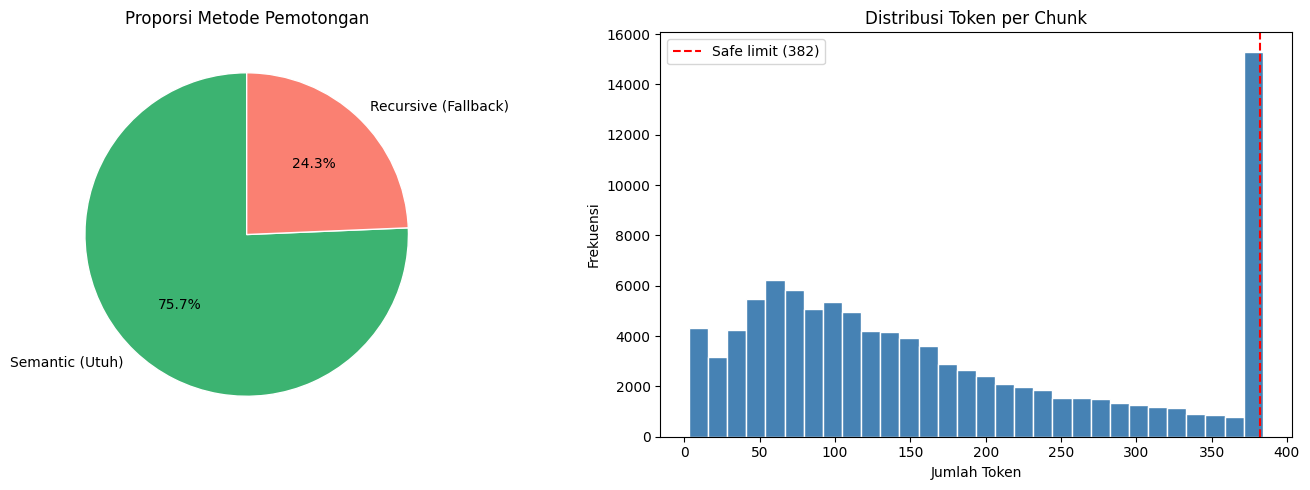


💾 Hasil disimpan: hybrid_chunks_result.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
# ─── RINGKASAN ────────────────────────────────────────────────────────────
total_chunks    = len(result_df)
semantic_count  = len(result_df[result_df['method_used'] == 'Semantic'])
recursive_count = len(result_df[result_df['method_used'] == 'Recursive-Fallback'])
exceeds_limit = result_df[result_df['chunk_tokens'] > TOKEN_LIMIT]

print('=' * 45)
print('🏆 RINGKASAN HYBRID CHUNKING')
print('=' * 45)
print(f'Total Chunks Akhir          : {total_chunks}')
print(f'➜ Jalur Semantic (Utuh)     : {semantic_count} ({(semantic_count/total_chunks)*100:.1f}%)')
print(f'➜ Jalur Fallback (Dipotong) : {recursive_count} ({(recursive_count/total_chunks)*100:.1f}%)')
print('-' * 45)

if len(exceeds_limit) == 0:
    print(f'✅ Chunks > {SAFE_LIMIT} token : 0 — SEMUA AMAN')
else:
    print(f'🚨 Chunks > {SAFE_LIMIT} token : {len(exceeds_limit)} — MASIH ADA YANG OVER!')
    print(exceeds_limit[['Agreement', 'article_name', 'chunk_tokens']].head())

print('=' * 45)
print(f'\nStatistik token per chunk:')
print(result_df['chunk_tokens'].describe().round(1))

# Visualisasi
labels = ['Semantic (Utuh)', 'Recursive (Fallback)']
sizes  = [semantic_count, recursive_count]
colors = ['mediumseagreen', 'salmon']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors,
            startangle=90, wedgeprops={'edgecolor': 'white'})
axes[0].set_title('Proporsi Metode Pemotongan')

axes[1].hist(result_df['chunk_tokens'], bins=30, color='steelblue', edgecolor='white')
axes[1].axvline(SAFE_LIMIT, color='red', linestyle='--', label=f'Safe limit ({SAFE_LIMIT})')
axes[1].set_title('Distribusi Token per Chunk')
axes[1].set_xlabel('Jumlah Token')
axes[1].set_ylabel('Frekuensi')
axes[1].legend()

plt.tight_layout()
plt.show()

# ─── DOWNLOAD HASIL ───────────────────────────────────────────────────────
output_file = 'hybrid_chunks_result.csv'
result_df.to_csv(output_file, index=False)
print(f'\n💾 Hasil disimpan: {output_file}')

from google.colab import files
files.download(output_file)
